<a href="https://colab.research.google.com/github/taehi5/Esaa_YB/blob/11%EC%A3%BC%EC%B0%A8---%EA%B3%BC%EC%A0%9C/ESAA_YB_Week11_01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

`파이썬 머신러닝 완벽가이드 ch5. 1~5 pg.308~337`


# 01. 회귀 소개

- 회귀: 여러 독립변수와 연속적인 종속변수 사이의 관계를 모델링해 값을 예측하는 방법임.
- 독립변수 X는 피처, 종속변수 y는 예측 대상임. 예: 방 개수·주택 연식으로 주택 가격을 예측함.
- 학습 과정에서 데이터에 잘 맞는 회귀 계수와 절편을 찾음.

$$\hat y = w_0 + w_1x_1 + \cdots + w_px_p$$



✅ 주요 선형 모델

- 일반 선형 회귀: 잔차 제곱합을 최소화함.
- 릿지: L2 규제로 계수 크기를 줄임.
- 라쏘: L1 규제로 일부 계수를 0으로 만들 수 있음.
- 엘라스틱넷: L1과 L2 규제를 함께 사용함.
- 로지스틱 회귀: 이름에 회귀가 들어가지만 분류에 사용하는 모델임.

❗ 다항 회귀도 회귀 계수에 대해 선형이면 선형 회귀에 해당함.

# 02. 단순 선형 회귀를 통한 회귀 이해

- 하나의 피처로 하나의 연속값을 예측함. `예측값 = 절편 + 기울기 × X`임.
- 잔차(residual)는 `실제값 - 예측값`임.
- 잔차를 그대로 더하면 양수와 음수가 상쇄되므로 제곱해 합한 RSS를 최소화함.

$$RSS = \sum_{i=1}^{N}(y_i-\hat y_i)^2$$

- OLS(최소제곱법)는 RSS를 최소화하는 계수를 구함.
- 학습 중 X와 y는 주어진 데이터이며, 비용 함수를 줄이기 위해 바꾸는 값은 w임.
- 아래 경사 하강법 예제는 RSS를 표본 수 N으로 나눈 MSE를 비용으로 사용함. 같은 데이터에서는 두 함수의 최솟값을 만드는 계수가 같음.

# 03. 비용 최소화하기 - 경사 하강법




## 1. 경사 하강법의 원리

- 현재 계수에서 비용 함수의 기울기를 계산하고, 기울기의 반대 방향으로 계수를 조금씩 바꿈.
- 학습률 η는 한 번에 이동하는 크기를 조절함.
- 너무 큰 학습률은 발산을 일으킬 수 있고, 너무 작은 학습률은 수렴이 느림.

$$w_j \leftarrow w_j-\eta\frac{\partial J}{\partial w_j}$$

$$J = \frac{1}{N}\sum_i(y_i-(w_0+w_1x_i))^2$$

$$\frac{\partial J}{\partial w_1}=-\frac{2}{N}\sum_i x_i(y_i-\hat y_i),\quad
\frac{\partial J}{\partial w_0}=-\frac{2}{N}\sum_i(y_i-\hat y_i)$$

✅ 계수 초기화 → 예측 → 기울기 계산 → 계수 업데이트를 반복함.

❗ 최소점에서는 비용 함수의 기울기가 0에 가까워짐. 미분 함수 자체의 최솟값을 찾는다는 뜻은 아님.

## 2. 실습 데이터 생성

- y = 4X + 6에 정규분포 잡음을 더한 표본 100개를 만듦.
- 잡음이 있으므로 추정한 기울기와 절편이 정확히 4와 6이 될 필요는 없음.

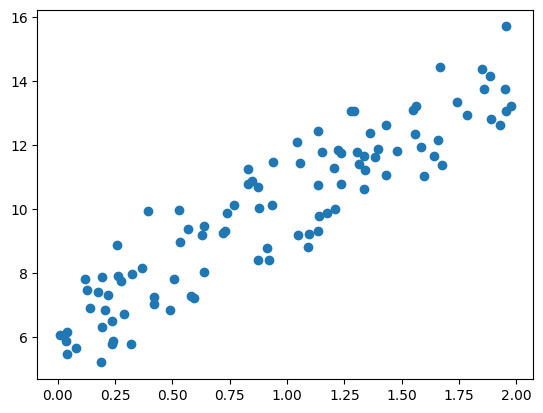

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

np.random.seed(0)
X = 2 * np.random.rand(100, 1)
y = 6 + 4 * X + np.random.randn(100, 1)

plt.scatter(X, y)

## 3. 비용 함수와 계수 업데이트

- get_cost(): 평균 제곱 오차를 반환함.
- get_weight_updates(): 학습률을 곱한 기울기를 반환함.
- 반환된 업데이트 값을 현재 계수에서 빼야 비용이 감소하는 방향으로 이동함.
- 이 실습은 단일 피처이며 X와 y를 모두 (N, 1) 형태로 사용함.

In [4]:
def get_cost(y, y_pred):
    N = len(y)
    cost = np.sum(np.square(y - y_pred)) / N
    return cost

In [6]:
# w1과 w0을 업데이트할 w1_update, w0_update를 반환
def get_weight_updates(w1, w0, X, y, learning_rate=0.01):
    N = len(y)

    # w1_update, w0_update를 각각 w1, w0과 동일한 크기의 0으로 초기화
    w1_update = np.zeros_like(w1)
    w0_update = np.zeros_like(w0)

    # 예측 배열을 계산하고 실제값과 예측값의 차이 계산
    y_pred = np.dot(X, w1.T) + w0
    diff = y - y_pred

    # w0_update를 dot 행렬 연산으로 구하기 위해 모두 1인 행렬 생성
    w0_factors = np.ones((N, 1))

    # w1과 w0을 업데이트할 w1_update와 w0_update 계산
    w1_update = -(2 / N) * learning_rate * np.dot(X.T, diff)
    w0_update = -(2 / N) * learning_rate * np.dot(w0_factors.T, diff)

    return w1_update, w0_update

In [7]:
# 입력 인자 iters로 주어진 횟수만큼 반복적으로 w1과 w0을 업데이트 적용함
def gradient_descent_steps(X, y, iters=10000):
    # w0과 w1을 모두 0으로 초기화
    w0 = np.zeros((1, 1))
    w1 = np.zeros((1, 1))

    # iters만큼 반복적으로 get_weight_updates()를 호출해 w1, w0 업데이트 수행
    for ind in range(iters):
        w1_update, w0_update = get_weight_updates(
            w1, w0, X, y, learning_rate=0.01
        )
        w1 = w1 - w1_update
        w0 = w0 - w0_update

    return w1, w0

In [8]:
def get_cost(y, y_pred):
    N = len(y)
    cost = np.sum(np.square(y - y_pred)) / N
    return cost


w1, w0 = gradient_descent_steps(X, y, iters=1000)
print("w1:{0:.3f} w0:{1:.3f}".format(w1[0, 0], w0[0, 0]))

y_pred = w1[0, 0] * X + w0
print('Gradient Descent Total Cost:{0:.4f}'.format(get_cost(y, y_pred)))

w1:4.022 w0:6.162
Gradient Descent Total Cost:0.9935


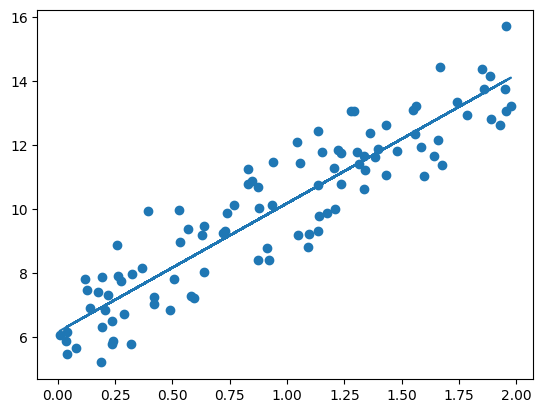

In [9]:
plt.scatter(X, y)
plt.plot(X, y_pred)

## 4. 미니 배치 확률적 경사 하강법


- 배치 경사 하강법: 전체 학습 표본
- 확률적 경사 하강법(SGD): 한 표본
- 미니 배치 경사 하강법: 일부 표본 묶음

- 아래는 교재의 함수명을 유지한 미니 배치 예제임. 매 반복마다 10개를 무작위로 추출함.
- 전체 표본을 쓰는 방식보다 한 번의 업데이트 비용이 작지만, 비용이 매번 감소한다는 보장은 없음.

In [10]:
def stochastic_gradient_descent_steps(X, y, batch_size=10, iters=1000):
    w0 = np.zeros((1, 1))
    w1 = np.zeros((1, 1))

    for ind in range(iters):
        np.random.seed(ind)

        # 전체 X, y 데이터에서 랜덤하게 batch_size만큼 추출해 저장
        stochastic_random_index = np.random.permutation(X.shape[0])
        sample_X = X[stochastic_random_index[0:batch_size]]
        sample_y = y[stochastic_random_index[0:batch_size]]

        # 추출된 데이터를 기반으로 업데이트 값 계산
        w1_update, w0_update = get_weight_updates(
            w1, w0, sample_X, sample_y, learning_rate=0.01
        )
        w1 = w1 - w1_update
        w0 = w0 - w0_update

    return w1, w0

In [11]:
w1, w0 = stochastic_gradient_descent_steps(X, y, iters=1000)
print("w1:", round(w1[0, 0], 3), "w0:", round(w0[0, 0], 3))

y_pred = w1[0, 0] * X + w0
print('Stochastic Gradient Descent Total Cost:{0:.4f}'.format(get_cost(y, y_pred)))

w1: 4.028 w0: 6.156
Stochastic Gradient Descent Total Cost:0.9937


## 5. 다중 회귀로 확장

- 피처가 M개이면 기울기 M개와 절편 1개를 학습함.
- 행렬로는 y_pred = X @ w + w0로 계산함.
- X의 맨 앞에 모두 1인 열을 붙이면 절편도 계수 벡터에 포함할 수 있음.
- 행렬 곱으로 여러 표본과 피처를 한 번에 처리함.

# 04. 사이킷런 LinearRegression을 이용한 보스턴 주택 가격 예측


## 1. LinearRegression 클래스

- OLS 방식으로 잔차 제곱합을 최소화하는 선형 회귀 모델임.
- fit_intercept=True: 절편을 계산함.
- n_jobs=1: 공지의 설정을 반영함.
- fit(X, y)로 학습하고 predict(X)로 예측함.
- coef_는 피처별 회귀 계수, intercept_는 절편임.
- 피처 사이의 선형 의존성이 강한 다중 공선성은 계수 추정을 불안정하게 만들 수 있음.

❗ 폐기된 normalize 인자는 사용하지 않음. 스케일 조정이 필요하면 전처리기를 별도로 사용함.

In [12]:
from sklearn.linear_model import LinearRegression

linear_regression_model = LinearRegression(fit_intercept=True, n_jobs=1)

## 2. 회귀 평가 지표

[지표]
- MAE: 절대 오차의 평균,작을수록 좋음
- MSE: 제곱 오차의 평균, 큰 오차에 더 큰 벌점을 줌
- RMSE: MSE의 제곱근, 목표값과 같은 단위
-  R²: 1- RSS / 실제값의 총제곱합, 1에 가까울수록 좋음, 음수도 가능함

$$R^2=1-\frac{\sum_i(y_i-\hat y_i)^2}{\sum_i(y_i-\bar y)^2}$$

- R²가 0이면 해당 평가 데이터의 평균을 예측하는 기준과 같은 제곱 오차임(정답이 상수가 아닌 경우).
- cross_val_score()는 클수록 좋은 점수로 통일하므로 오차 지표에 neg_를 붙임.
- neg_mean_squared_error의 반환값에 -1을 곱해야 원래 MSE가 됨.
- 버전 호환성을 위해 RMSE는 np.sqrt(mean_squared_error(...))로 계산함.

## 3. LinearRegression을 이용해 보스턴 주택 가격 회귀 구현

- 공지에 따라 load_boston() 대신 원본 텍스트를 읽음.
- 한 표본이 두 줄에 나뉘어 있으므로 짝수 인덱스 행 11개 값과 다음 행의 앞 2개 값을 연결함.
- 다음 행의 세 번째 값이 목표값임. 피처 13개와 PRICE를 합쳐 (506, 14)가 됨.
- PRICE는 주택 가격 중앙값이며 단위는 1,000달러임.


[피처 및 의미]
- CRIM : ZN / INDUS, 범죄율 / 대형 주거용 부지 비율 / 비소매 상업용 토지 비율
- CHAS / NOX|찰스강 경계 여부 / 질소산화물 농도
- RM / AGE|주택당 평균 방 개수 / 1940년 이전 건축 주택 비율
- DIS / RAD|고용 중심지까지의 가중 거리 / 고속도로 접근성 지수
- TAX / PTRATIO|재산세율 / 학생 대 교사 비율
- B / LSTAT, 인종 비율을 가공한 역사적 지표 / 원자료의 저소득층 관련 비율

❗ B는 원자료에서 `1000(Bk - 0.63)²`로 만든 값이며 단순 인구 비율이 아님. 이 데이터는 윤리적 문제로 사이킷런 내장 데이터셋에서 제거되었으며, 여기서는 지정된 교재 실습을 재현함.

In [13]:
import numpy as np
import pandas as pd
from IPython.display import display

data_url = "http://lib.stat.cmu.edu/datasets/boston"

raw_df = pd.read_csv(data_url, sep=r"\s+", skiprows=22, header=None)

data = np.hstack([raw_df.values[::2, :], raw_df.values[1::2, :2]])
target = raw_df.values[1::2, 2]

feature_names = [
    'CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE',
    'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT'
]

bostonDF = pd.DataFrame(data, columns=feature_names)
bostonDF['PRICE'] = target

print('Boston 데이터 세트 크기 :', bostonDF.shape)
display(bostonDF.head())

Boston 데이터 세트 크기 : (506, 14)


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,PRICE
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,396.90,5.33,36.2


## 4. 피처와 가격의 관계 시각화

- regplot()으로 산점도와 단일 피처의 회귀선을 함께 그림.
- RM이 클수록 가격이 높고, LSTAT이 클수록 가격이 낮은 경향을 확인함.
- 단일 피처 그래프의 관계가 다른 피처를 통제한 효과나 인과관계를 의미하지는 않음.

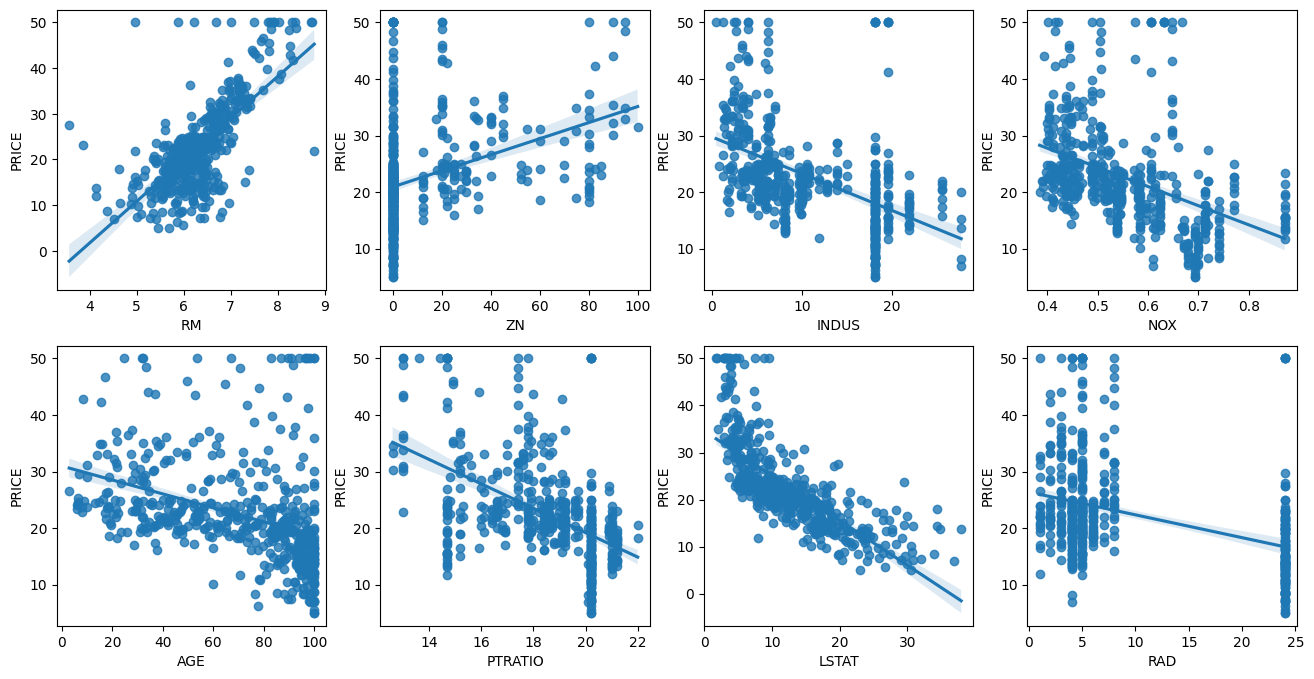

In [16]:
import seaborn as sns
# 2개의 행과 4개의 열을 가진 subplots를 이용
fig, axs = plt.subplots(figsize=(16, 8), ncols=4, nrows=2)
lm_features = ['RM', 'ZN', 'INDUS', 'NOX', 'AGE', 'PTRATIO', 'LSTAT', 'RAD']

for i, feature in enumerate(lm_features):
    row = int(i / 4)
    col = i % 4

    # 시본의 regplot을 이용해 산점도와 선형 회귀 직선을 함께 표현
    sns.regplot(x=feature, y='PRICE', data=bostonDF, ax=axs[row][col])

## 5. 학습·예측·평가

- PRICE를 y, 나머지 13개 피처를 X로 분리함.
- 테스트 비율 30%, random_state=156으로 교재와 동일하게 분할함.
- 테스트 데이터는 학습에 사용하지 않고 예측 성능 평가에 사용함.

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

y_target = bostonDF['PRICE']
X_data = bostonDF.drop(['PRICE'], axis=1, inplace=False)

X_train, X_test, y_train, y_test = train_test_split(
    X_data, y_target, test_size=0.3, random_state=156
)

# 선형 회귀 OLS로 학습/예측/평가 수행
lr = LinearRegression()
lr.fit(X_train, y_train)

y_preds = lr.predict(X_test)
mse = mean_squared_error(y_test, y_preds)
rmse = np.sqrt(mse)

print('MSE : {0:.3f}, RMSE : {1:.3f}'.format(mse, rmse))
print('Variance score : {0:.3f}'.format(r2_score(y_test, y_preds)))

MSE : 17.297, RMSE : 4.159
Variance score : 0.757


## 6. 절편과 회귀 계수 확인

- 양수 계수는 다른 피처가 같을 때 해당 피처 증가에 따라 예측값이 증가하는 방향임.
- 피처 단위가 서로 다르므로 계수의 절댓값만으로 중요도 순위를 판단하면 안 됨.

In [18]:
print('절편 값:', lr.intercept_)
print('회귀 계수값:', np.round(lr.coef_, 1))

절편 값: 40.995595172164826
회귀 계수값: [ -0.1   0.1   0.    3.  -19.8   3.4   0.   -1.7   0.4  -0.   -0.9   0.
  -0.6]


In [19]:
# 회귀 계수를 큰 값 순으로 정렬하기 위해 Series로 생성. 인덱스 칼럼명에 유의
coeff = pd.Series(data=np.round(lr.coef_, 1), index=X_data.columns)
coeff.sort_values(ascending=False)

,0
RM,3.4
CHAS,3.0
RAD,0.4
ZN,0.1
INDUS,0.0
B,0.0
TAX,-0.0
AGE,0.0
CRIM,-0.1
LSTAT,-0.6


## 7. 5폴드 교차 검증
- 전체 데이터를 5개 폴드로 나누고 각 폴드를 한 번씩 검증용으로 사용함.
- 음수 MSE를 양수로 돌린 뒤 제곱근을 구해 폴드별 RMSE를 계산함.
- 폴드별 RMSE의 평균과 평균 MSE의 제곱근은 서로 다른 값임.
- 앞의 단일 분할 평가와 검증 구성이 다르므로 수치를 같은 조건의 결과로 비교하면 안 됨.

In [20]:
from sklearn.model_selection import cross_val_score

y_target = bostonDF['PRICE']
X_data = bostonDF.drop(['PRICE'], axis=1, inplace=False)
lr = LinearRegression()

# cross_val_score()로 5폴드 세트의 MSE를 구한 뒤 이를 기반으로 RMSE 계산
neg_mse_scores = cross_val_score(
    lr, X_data, y_target, scoring="neg_mean_squared_error", cv=5
)
rmse_scores = np.sqrt(-1 * neg_mse_scores)
avg_rmse = np.mean(rmse_scores)

# scoring="neg_mean_squared_error"로 반환된 값은 모두 음수
print('5 folds의 개별 Negative MSE scores:', np.round(neg_mse_scores, 2))
print('5 folds의 개별 RMSE scores:', np.round(rmse_scores, 2))
print('5 folds의 평균 RMSE: {0:.3f}'.format(avg_rmse))

5 folds의 개별 Negative MSE scores: [-12.46 -26.05 -33.07 -80.76 -33.31]
5 folds의 개별 RMSE scores: [3.53 5.1  5.75 8.99 5.77]
5 folds의 평균 RMSE: 5.829


# 05. 다항 회귀와 과(대)적합/과소적합 이해


## 1. 다항 회귀의 원리

- 원래 피처를 제곱·세제곱·교차항으로 확장해 곡선 관계를 표현함.
- 예: y = w0 + w1*x1 + w2*x2 + w3*x1*x2 + w4*x1² + w5*x2²
- 변환된 피처를 새로운 변수로 보면 계수에 대해 선형이므로 선형 회귀임.
- PolynomialFeatures는 피처 변환만 수행함. 회귀 학습은 LinearRegression이 수행함.
- degree=2이면 2차 이하의 항을 생성함. 기본값은 상수항도 포함함.

In [21]:
from sklearn.preprocessing import PolynomialFeatures
import numpy as np

# 다항식으로 변환할 단항식 생성, [[0, 1], [2, 3]]의 2×2 행렬 생성
X = np.arange(4).reshape(2, 2)
print('일차 단항식 계수 피처:\n', X)

# degree=2인 2차 다항식으로 변환하기 위해 PolynomialFeatures를 이용
poly = PolynomialFeatures(degree=2)
poly.fit(X)
poly_ftr = poly.transform(X)

print('변환된 2차 다항식 계수 피처:\n', poly_ftr)

일차 단항식 계수 피처:
 [[0 1]
 [2 3]]
변환된 2차 다항식 계수 피처:
 [[1. 0. 1. 0. 0. 1.]
 [1. 2. 3. 4. 6. 9.]]


## 2. 3차 다항 회귀 적용

- 목표식은 y = 1 + 2*x1 + 3*x1² + 4*x2³임.
- 2개 피처를 3차 다항식으로 바꾸면 상수항을 포함해 10개 열이 됨.
- 표본 2개만으로 많은 계수를 구하므로 정답식을 유일하게 복원할 수 없음. 학습값이 맞더라도 새 데이터 예측력이 보장되지는 않음.

In [22]:
def polynomial_func(X):
    y = 1 + 2 * X[:, 0] + 3 * X[:, 0] ** 2 + 4 * X[:, 1] ** 3
    return y


X = np.arange(4).reshape(2, 2)
print('일차 단항식 계수 feature:\n', X)

y = polynomial_func(X)
print('삼차 다항식 결정값:\n', y)

일차 단항식 계수 feature:
 [[0 1]
 [2 3]]
삼차 다항식 결정값:
 [  5 125]


In [23]:
# 3차 다항식 변환
poly_ftr = PolynomialFeatures(degree=3).fit_transform(X)
print('3차 다항식 계수 feature:\n', poly_ftr)

# 3차 다항식 피처와 결정값으로 학습 후 회귀 계수 확인
model = LinearRegression()
model.fit(poly_ftr, y)

print('Polynomial 회귀 계수:\n', np.round(model.coef_, 2))
print('Polynomial 회귀 Shape:', model.coef_.shape)

3차 다항식 계수 feature:
 [[ 1.  0.  1.  0.  0.  1.  0.  0.  0.  1.]
 [ 1.  2.  3.  4.  6.  9.  8. 12. 18. 27.]]
Polynomial 회귀 계수:
 [0.   0.18 0.18 0.36 0.54 0.72 0.72 1.08 1.62 2.34]
Polynomial 회귀 Shape: (10,)


## 3. Pipeline으로 변환과 학습 연결

- PolynomialFeatures → LinearRegression을 하나의 모델처럼 사용함.
- fit()은 변환과 학습을 순서대로 수행하고, predict()도 같은 피처 변환을 적용함.
- 교차 검증에서도 각 학습 폴드 안에서 변환기를 학습하도록 구성할 수 있음.

In [24]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
import numpy as np


def polynomial_func(X):
    y = 1 + 2 * X[:, 0] + 3 * X[:, 0] ** 2 + 4 * X[:, 1] ** 3
    return y


# Pipeline 객체로 Polynomial Feature 변환과 Linear Regression을 연결
model = Pipeline([
    ('poly', PolynomialFeatures(degree=3)),
    ('linear', LinearRegression())
])

X = np.arange(4).reshape(2, 2)
y = polynomial_func(X)

model = model.fit(X, y)

print('Polynomial 회귀 계수:\n',
      np.round(model.named_steps['linear'].coef_, 2))

Polynomial 회귀 계수:
 [0.   0.18 0.18 0.36 0.54 0.72 0.72 1.08 1.62 2.34]


## 4. 다항 회귀를 이용한 과소적합·과적합 비교

- 실제 함수 cos(1.5πX)에 잡음을 추가한 표본 30개를 사용함.
- 차수 1, 4, 15를 비교하고 10폴드 교차 검증 MSE를 계산함.
- 1차: 곡선의 패턴을 충분히 표현하지 못해 과소적합하기 쉬움.
- 4차: 이 예제에서는 적절한 복잡도로 패턴을 근사함.
- 15차: 학습 표본의 잡음에 민감하게 맞추면서 새 데이터의 오차가 커질 수 있음.

❗ 높은 차수가 항상 좋은 결과를 주지는 않음. 학습 오차와 교차 검증 오차를 구분해 확인함.

❗ 15차 다항식은 수치적으로 불안정할 수 있음. NumPy·SciPy·사이킷런의 버전과 유효 랭크 판정에 따라 계수와 교차 검증 MSE가 교재와 크게 달라질 수 있음. 이 노트북의 검증 환경에서는 1차 약 0.408, 4차 약 0.043, 15차 약 0.220이었으며 4차의 검증 오차가 가장 작았음. 교재의 매우 큰 15차 MSE가 그대로 재현되는 것을 전제로 해석하지 않음.


In [25]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score

%matplotlib inline

# 임의의 값으로 구성된 X값에 대해 코사인 변환 값을 반환
def true_fun(X):
    return np.cos(1.5 * np.pi * X)


# X는 0부터 1까지 30개의 임의의 값을 순서대로 샘플링한 데이터
np.random.seed(0)
n_samples = 30
X = np.sort(np.random.rand(n_samples))

# y는 코사인 기반의 true_fun()에서 약간의 노이즈를 더한 값
y = true_fun(X) + np.random.randn(n_samples) * 0.1


Degree 1 회귀 계수는 [-1.61] 입니다.
Degree 1 MSE는 0.4077289625098685 입니다.

Degree 4 회귀 계수는 [  0.47 -17.79  23.59  -7.26] 입니다.
Degree 4 MSE는 0.04320874987232064 입니다.

Degree 15 회귀 계수는 [-2.98293000e+03  1.03899390e+05 -1.87416123e+06  2.03716219e+07
 -1.44873283e+08  7.09315363e+08 -2.47065792e+09  6.24561050e+09
 -1.15676510e+10  1.56894936e+10 -1.54006023e+10  1.06457264e+10
 -4.91377530e+09  1.35919645e+09 -1.70380786e+08] 입니다.
Degree 15 MSE는 181238256.56423894 입니다.


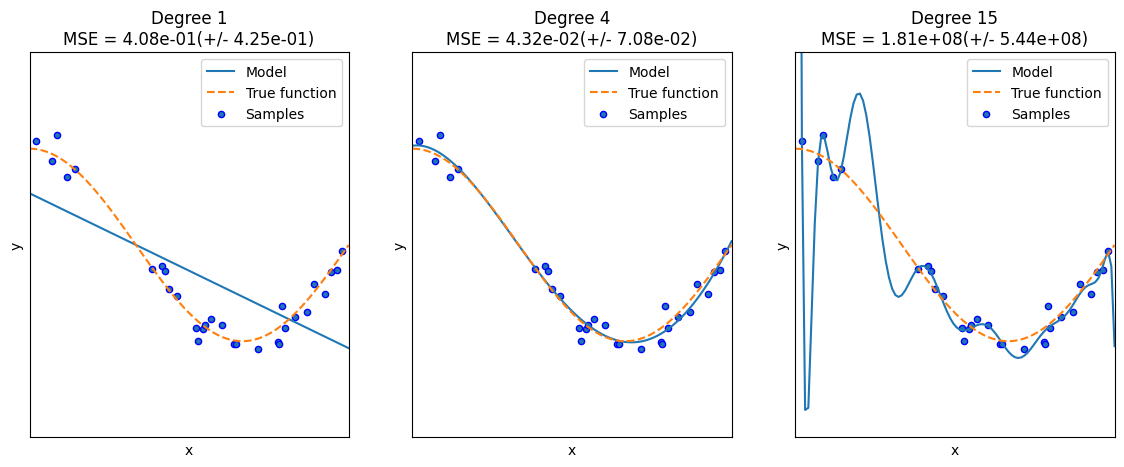

In [26]:
plt.figure(figsize=(14, 5))
degrees = [1, 4, 15]

# 다항 회귀의 차수(degree)를 1, 4, 15로 각각 변화시키면서 비교
for i in range(len(degrees)):
    ax = plt.subplot(1, len(degrees), i + 1)
    plt.setp(ax, xticks=(), yticks=())

    # 개별 degree별로 Polynomial 변환
    polynomial_features = PolynomialFeatures(
        degree=degrees[i], include_bias=False
    )
    linear_regression = LinearRegression()
    pipeline = Pipeline([
        ("polynomial_features", polynomial_features),
        ("linear_regression", linear_regression)
    ])
    pipeline.fit(X.reshape(-1, 1), y)

    # 교차 검증으로 다항 회귀 평가
    scores = cross_val_score(
        pipeline, X.reshape(-1, 1), y,
        scoring="neg_mean_squared_error", cv=10
    )

    # named_steps['객체명']을 이용해 회귀 계수 추출
    coefficients = pipeline.named_steps['linear_regression'].coef_
    print('\nDegree {0} 회귀 계수는 {1} 입니다.'.format(
        degrees[i], np.round(coefficients, 2)
    ))
    print('Degree {0} MSE는 {1} 입니다.'.format(
        degrees[i], -1 * np.mean(scores)
    ))

    # 0부터 1까지 테스트 데이터 세트를 100개로 나눠 예측 수행
    X_test = np.linspace(0, 1, 100)

    # 예측값 곡선
    plt.plot(
        X_test, pipeline.predict(X_test[:, np.newaxis]), label="Model"
    )

    # 실제 값 곡선
    plt.plot(X_test, true_fun(X_test), '--', label="True function")
    plt.scatter(X, y, edgecolor='b', s=20, label="Samples")

    plt.xlabel("x")
    plt.ylabel("y")
    plt.xlim((0, 1))
    plt.ylim((-2, 2))
    plt.legend(loc="best")
    plt.title("Degree {}\nMSE = {:.2e}(+/- {:.2e})".format(
        degrees[i], -scores.mean(), scores.std()
    ))

plt.show()

## 5. 편향-분산 트레이드오프

[상태]
- 단순한 모델: 편향 높음, 분산 낮음,중요한 패턴을 놓치는 과소적합
- 복잡한 모델: 편향 낮음, 분산 높음, 학습 표본의 변화에 민감한 과적합

- 편향: 여러 학습 데이터로 만든 모델의 평균 예측과 실제 함수 사이의 차이임.
- 분산: 학습 데이터가 달라질 때 모델의 예측이 얼마나 달라지는지 나타냄.
- 제곱 오차는 일반적인 가정에서 편향² + 분산 + 줄일 수 없는 잡음으로 분해함.
- 복잡도를 높이면 편향이 줄어드는 대신 분산이 커지는 경향이 있음.
- 목표는 학습 오차만 최소화하는 것이 아니라, 새 데이터에서 전체 예측 오차가 작은 복잡도를 선택하는 것임.

